# Fluid somatostatin-like immunoreactivity in parkinsonian cohorts

Cross-study comparison figure for the section *Parkinson's Disease and Lewy Body Dementias*.

**Data source.** Four radioimmunoassay cohorts. Every plotted number is quoted verbatim from the `source` string stored beside it; sample counts are quoted from the `n_source` string. Nothing is converted, rescaled, normalised or back-calculated.

**Caveats carried in the display.** Fluid compartments differ (lumbar CSF; CSF of unstated compartment; lateral ventricular fluid), units differ (fmol/ml versus pg/ml) and are never converted, comparator groups differ (senile controls; benign essential tremor; neurologically asymptomatic subjects), disease stage differs (untreated de novo versus established and partly L-DOPA-treated), and the direction of effect is not shared - Espino 1995 reports an increase. Error bars are drawn only where the source names the dispersion type: SEM for Cramer 1985 and SD for Cramer 2008, the latter inherited from the substance-P term of the same sentence. Group sizes are not reported for Cramer 2008 or Cramer 1985. All four values are abstract-derived.

In [ ]:
# Figure: fluid somatostatin-like immunoreactivity in parkinsonian cohorts.
# Every plotted value is quoted verbatim from the source sentence recorded beside it.
# Compartments and units are never merged: one panel per unit/compartment group,
# each with its own axis. No conversion, normalisation or percent-of-control ratio.
import os
import sys

# Resolve the directory that holds shared_style.py so the notebook runs from the
# repository root or from figures/notebooks.
BASE = next(p for p in (".", "figures/notebooks", os.path.join(os.getcwd(), "figures", "notebooks"))
            if os.path.exists(os.path.join(p, "shared_style.py")))
sys.path.insert(0, BASE)
FIGDIR = os.path.normpath(os.path.join(BASE, ".."))
import matplotlib.pyplot as plt
from shared_style import COLORS, apply_style, save_figure

apply_style()

## Entries, with the verbatim source sentence stored beside every value

In [ ]:
ENTRIES = [
    dict(entry_id="S05-C01-E1", panel="A", label="Cramer 2008\nlumbar CSF",
         patient=19.8, comparator=32.5, patient_err=9.0, comparator_err=12.0,
         err_label="SD (inherited)", direction="decrease",
         notes=["group size not reported"],
         source="The mean SLI level was significantly lower in the group of patients with "
                "Parkinson's disease (19.8 +/- 9.0 fmol/ml). Mean SPLI and SLI levels in the "
                "control group were 8.1 +/- 2.0 (SD) and 32.5 +/- 12.0 fmol/ml, respectively."),
    dict(entry_id="S05-C01-E2", panel="A", label="Strittmatter 1992\nCSF, compartment\nnot stated",
         patient=21.4, comparator=29.5, patient_err=None, comparator_err=None,
         err_label=None, direction="decrease",
         notes=["+/- 8.1 and +/- 9.4,\ndispersion type\nnot stated", "n = 38 patients"],
         source="The mean somatostatin-like immunoreactivity (SLI) level in the cerebrospinal "
                "fluid (CSF) was significantly lower in parkinsonian patients (21.4 +/- 8.1 fmol "
                "ml-1) compared to senile control patients (29.5 +/- 9.4 fmol ml-1).",
         n_source="In 38 old aged parkinsonian patients, two major subgroups could be "
                  "established: one with predominant akinesia, rigidity, postural instability "
                  "and accompanying cognitive impairment..."),
    dict(entry_id="S05-C01-E3", panel="B", label="Espino 1995\nCSF, compartment\nnot specified",
         patient=107.9, comparator=73.5, patient_err=None, comparator_err=None,
         err_label=None, direction="increase",
         notes=["+/- 9.8 and +/- 8.4,\ndispersion type not stated",
                "twenty-three patients;\n26 comparators"],
         source="CSF-SLI content was found to be significantly higher in patients with "
                "parkinsonian syndrome (107.9 +/- 9.8 pg/ml) than in control subjects "
                "(73.5 +/- 8.4 pg/ml).",
         n_source="Somatostatin-like immunoreactivity levels (SLI) in cerebrospinal fluid (CSF) "
                  "were determined in twenty-three patients with untreated parkinsonian syndrome "
                  "(15 with Idiopathic Parkinson's disease (IPD) and 8 with other forms of "
                  "parkinsonism) at the moment of clinical diagnosis (mean duration of disease "
                  "1.1 +/- 0.2 years), and in 26 subjects without neurological symptoms."),
    dict(entry_id="S05-C01-E4", panel="C", label="Cramer 1985\nlateral ventricular\nfluid",
         patient=42.9, comparator=65.3, patient_err=2.9, comparator_err=9.7,
         err_label="SEM", direction="decrease",
         notes=["group size not reported"],
         source="Mean SLI levels were significantly lower in patients with Parkinson's disease "
                "(mean +/- SEM); 42.9 +/- 2.9 fmol/ml) and in patients with dystonic syndromes "
                "(39.4 +/- 3.2) than in patients with benign essential tremor (65.3 +/- 9.7)."),
]

PANELS = {
    "A": dict(title="A   fmol/ml: lumbar CSF and CSF\nof unstated compartment",
              unit="somatostatin-like immunoreactivity (fmol/ml)", ylim=(0, 55)),
    "B": dict(title="B   pg/ml: CSF,\ncompartment not specified",
              unit="somatostatin-like immunoreactivity (pg/ml)", ylim=(0, 135)),
    "C": dict(title="C   fmol/ml: lateral\nventricular fluid",
              unit="somatostatin-like immunoreactivity (fmol/ml)", ylim=(0, 90)),
}

## Figure construction

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(7.09, 5.0),
                         gridspec_kw=dict(width_ratios=[2.0, 1.0, 1.0], wspace=0.62))

for ax, pid in zip(axes, ["A", "B", "C"]):
    rows = [e for e in ENTRIES if e["panel"] == pid]
    cfg = PANELS[pid]
    for i, e in enumerate(rows):
        xp, xc = i - 0.16, i + 0.16
        ax.plot([xp, xc], [e["patient"], e["comparator"]],
                color=COLORS["neutral_gray"], lw=0.9, zorder=1)
        ax.errorbar(xp, e["patient"],
                    yerr=e["patient_err"] if e["patient_err"] is not None else None,
                    fmt="D", ms=7, color=COLORS[e["direction"]],
                    markeredgecolor="black", markeredgewidth=0.8, capsize=3,
                    ecolor=COLORS[e["direction"]], elinewidth=1.0, zorder=3)
        ax.errorbar(xc, e["comparator"],
                    yerr=e["comparator_err"] if e["comparator_err"] is not None else None,
                    fmt="D", ms=7, color="white",
                    markeredgecolor=COLORS["excitatory"], markeredgewidth=1.1, capsize=3,
                    ecolor=COLORS["excitatory"], elinewidth=1.0, zorder=3)
        ax.annotate(("%.1f" % e["patient"]), (xp, e["patient"]), textcoords="offset points",
                    xytext=(-4, 9), ha="right", fontsize=8)
        ax.annotate(("%.1f" % e["comparator"]), (xc, e["comparator"]), textcoords="offset points",
                    xytext=(4, 9), ha="left", fontsize=8)
        ytext = 0.04 * cfg["ylim"][1]
        for j, note in enumerate(e["notes"]):
            ha = "left" if (len(rows) > 1 and i == 0) else ("right" if len(rows) > 1 else "center")
            xoff = -0.5 if ha == "left" else (0.5 if ha == "right" else 0.0)
            ax.annotate(note, (i + xoff, ytext + j * 0.13 * cfg["ylim"][1]), ha=ha,
                        va="bottom", fontsize=7.0, color=COLORS["excitatory"])
    ax.set_xticks(range(len(rows)))
    ax.set_xticklabels([e["label"] + ("\nerror bars: " + e["err_label"] if e["err_label"]
                                      else "\nno error bar drawn") for e in rows], fontsize=8)
    ax.set_xlim(-0.6, len(rows) - 0.4)
    ax.set_ylim(*cfg["ylim"])
    ax.set_ylabel(cfg["unit"], fontsize=9)
    ax.set_title(cfg["title"], fontsize=9, loc="left", pad=10)

axes[1].annotate("reported as an INCREASE", (0.0, 128), ha="center", fontsize=8,
                 color=COLORS["increase"], fontweight="bold")

handles = [
    plt.Line2D([], [], marker="D", ls="", ms=7, color=COLORS["decrease"],
               markeredgecolor="black", label="parkinsonian group, reported decrease"),
    plt.Line2D([], [], marker="D", ls="", ms=7, color=COLORS["increase"],
               markeredgecolor="black", label="parkinsonian group, reported increase"),
    plt.Line2D([], [], marker="D", ls="", ms=7, color="white",
               markeredgecolor=COLORS["excitatory"], label="each study's own comparator group"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.09), fontsize=8)
fig.text(0.5, -0.145, "heterogeneous comparison - values not pooled; units and compartments "
                      "differ and no axis is shared between panels",
         ha="center", fontsize=8, style="italic", color=COLORS["excitatory"])
fig.text(0.5, -0.185, "all four values extracted from the source abstracts; full text was not "
                      "accessible for any entry in this panel set",
         ha="center", fontsize=7.5, color=COLORS["excitatory"])

## Save at the document standard (300 dpi, white background)

In [ ]:
save_figure(fig, os.path.join(FIGDIR, "fig_sec5_csf_somatostatin_parkinson_cohorts.png"))

## Rendered figure

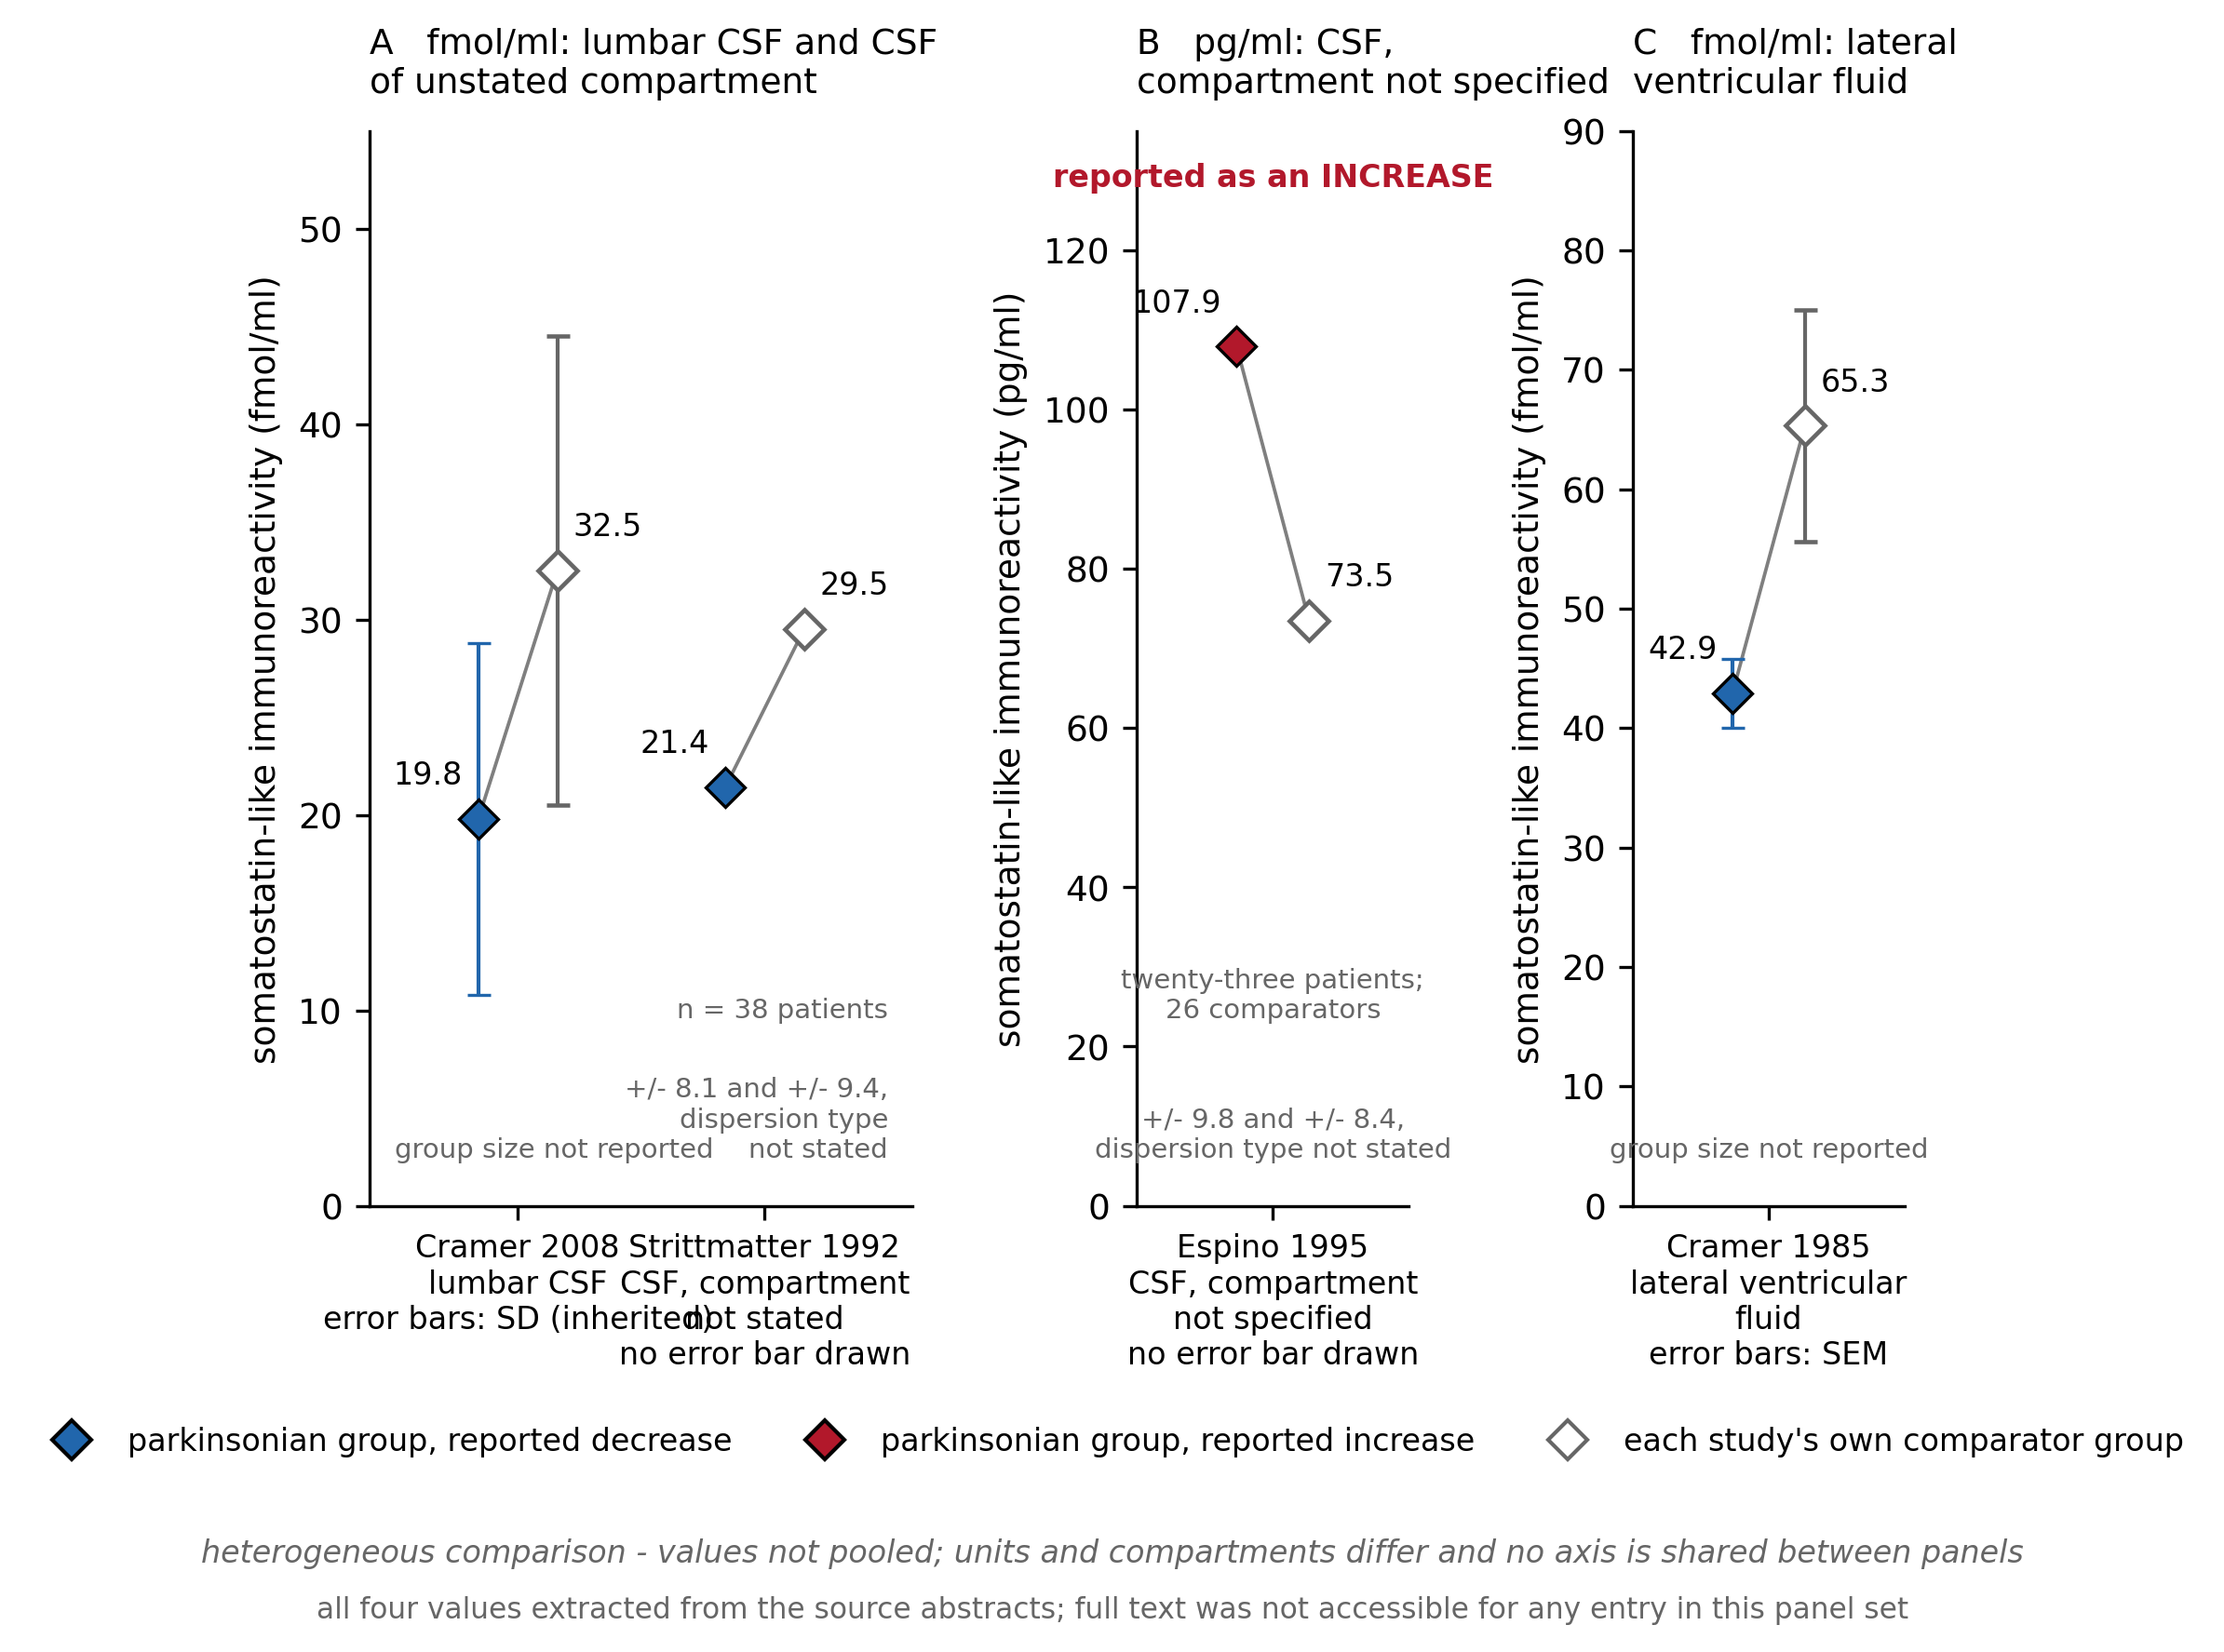

In [ ]:
fig